# PathSnap — Dataset Exploration & Understanding

**Phase 2 EDA notebook**

This notebook creates reproducible dataset inventory, GPS trajectory, road-network, reference-route and geographical outputs from the supplied PathSnap trip files.

**Important safeguards**
- This notebook only reads raw data; it does not modify the original files.
- Run cells from top to bottom.
- Keep trips intact; do not randomly split GPS observations.
- Evaluator-testing data must not be used for development decisions.
- Preliminary numbers from earlier discussion are hypotheses to verify here. The notebook's computed outputs are the evidence.


## 0. Environment and paths

Expected extracted layout:

```text
PathSnap_EDA_Project/
├── data/
│   └── raw/
│       └── Student folder/
│           ├── training/
│           └── student_test/
└── notebooks/
    └── 01_dataset_exploration.ipynb
```

Extract `Student folder.zip` into `data/raw/`. If your extracted folder has a different name or nesting, change `DATA_ROOT` below.


In [1]:
import sys
import numpy as np
import pandas as pd

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

Python executable: /Users/kcnandan/Desktop/PathSnap_EDA_Project/.venv/bin/python
Python version: 3.11.18 (main, Oct 25 2026, 19:41:29) [Clang 21.0.0 (clang-2100.3.34.2)]
NumPy version: 2.4.6
Pandas version: 3.1.1


In [3]:
from pathlib import Path
import os, sys, math, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_ROOT = PROJECT_ROOT / "data" / "raw" / "Student folder"
OUTPUT_ROOT = PROJECT_ROOT / "outputs"
TABLE_DIR = OUTPUT_ROOT / "tables"
FIGURE_DIR = OUTPUT_ROOT / "figures"
MAP_DIR = OUTPUT_ROOT / "maps"

for folder in [TABLE_DIR, FIGURE_DIR, MAP_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT.resolve())
print("Dataset root:", DATA_ROOT.resolve())
print("Dataset root exists:", DATA_ROOT.exists())


Project root: /Users/kcnandan/Desktop/PathSnap_EDA_Project
Dataset root: /Users/kcnandan/Desktop/PathSnap_EDA_Project/data/raw/Student folder
Dataset root exists: True


## 1. Discover partitions and trips

We inspect the directory structure instead of assuming every trip is identical.


In [4]:
PARTITIONS = ["train", "student_test"]

def discover_trips(data_root: Path):
    records = []
    for partition in PARTITIONS:
        part_dir = data_root / partition
        if not part_dir.exists():
            warnings.warn(f"Partition folder not found: {part_dir}")
            continue
        for trip_dir in sorted(p for p in part_dir.iterdir() if p.is_dir()):
            trip_id = trip_dir.name
            expected = {
                ext: trip_dir / f"{trip_id}.{ext}"
                for ext in ["track", "nodes", "arcs", "route"]
            }
            rec = {"partition": partition, "trip_id": trip_id, "folder": str(trip_dir)}
            for ext, path in expected.items():
                rec[f"{ext}_exists"] = path.exists()
                rec[f"{ext}_bytes"] = path.stat().st_size if path.exists() else np.nan
                rec[f"{ext}_path"] = str(path) if path.exists() else None
            records.append(rec)
    return pd.DataFrame(records)

inventory = discover_trips(DATA_ROOT)
display(inventory.head())
print("Trips discovered:", len(inventory))
print(inventory.groupby("partition")["trip_id"].nunique())
inventory.to_csv(TABLE_DIR / "trip_file_inventory.csv", index=False)


,partition,trip_id,folder,track_exists,track_bytes,track_path,nodes_exists,nodes_bytes,nodes_path,arcs_exists,arcs_bytes,arcs_path,route_exists,route_bytes,route_path
0,train,00000001,/Users/kcnandan/Desktop/PathSnap_EDA_Project/d...,True,40975,/Users/kcnandan/Desktop/PathSnap_EDA_Project/d...,True,1687371,/Users/kcnandan/Desktop/PathSnap_EDA_Project/d...,True,1948474,/Users/kcnandan/Desktop/PathSnap_EDA_Project/d...,True,3119,/Users/kcnandan/Desktop/PathSnap_EDA_Project/d...
1,train,00000002,/Users/kcnandan/Desktop/PathSnap_EDA_Project/d...,True,238085,/Users/kcnandan/Desktop/PathSnap_EDA_Project/d...,True,158720,/Users/kcnandan/Desktop/PathSnap_EDA_Project/d...,True,156519,/Users/kcnandan/Desktop/PathSnap_EDA_Project/d...,True,1398,/Users/kcnandan/Desktop/PathSnap_EDA_Project/d...
2,train,00000003,/Users/kcnandan/Desktop/PathSnap_EDA_Project/d...,True,26164,/Users/kcnandan/Desktop/PathSnap_EDA_Project/d...,True,182760,/Users/kcnandan/Desktop/PathSnap_EDA_Project/d...,True,175733,/Users/kcnandan/Desktop/PathSnap_EDA_Project/d...,True,411,/Users/kcnandan/Desktop/PathSnap_EDA_Project/d...
3,train,00000004,/Users/kcnandan/Desktop/PathSnap_EDA_Project/d...,True,34982,/Users/kcnandan/Desktop/PathSnap_EDA_Project/d...,True,147000,/Users/kcnandan/Desktop/PathSnap_EDA_Project/d...,True,149738,/Users/kcnandan/Desktop/PathSnap_EDA_Project/d...,True,1582,/Users/kcnandan/Desktop/PathSnap_EDA_Project/d...
4,train,00000005,/Users/kcnandan/Desktop/PathSnap_EDA_Project/d...,True,33378,/Users/kcnandan/Desktop/PathSnap_EDA_Project/d...,True,17960,/Users/kcnandan/Desktop/PathSnap_EDA_Project/d...,True,12351,/Users/kcnandan/Desktop/PathSnap_EDA_Project/d...,True,421,/Users/kcnandan/Desktop/PathSnap_EDA_Project/d...


Trips discovered: 90
partition
student_test    10
train           80
Name: trip_id, dtype: int64


## 2. Read raw trip files

The documented formats are whitespace-separated and headerless:
- `.track`: longitude, latitude, timestamp (seconds)
- `.nodes`: longitude, latitude
- `.arcs`: from-node ID, to-node ID
- `.route`: chronological arc IDs

The reader validates column counts and preserves original row indices as IDs.


In [5]:

def read_trip(trip_folder: Path, trip_id: str):

    paths = {
        ext: trip_folder / f"{trip_id}.{ext}"
        for ext in ["track", "nodes", "arcs", "route"]
    }

    missing = [str(p.name) for p in paths.values() if not p.exists()]

    if missing:
        raise FileNotFoundError(
            f"{trip_id}: missing files {missing}"
        )

    # Correctly parse tab/space-separated files
    track = pd.read_csv(
        paths["track"],
        sep=r"\s+",
        engine="python",
        header=None,
        names=["longitude", "latitude", "timestamp"]
    )

    nodes = pd.read_csv(
        paths["nodes"],
        sep=r"\s+",
        engine="python",
        header=None,
        names=["longitude", "latitude"]
    )

    arcs = pd.read_csv(
        paths["arcs"],
        sep=r"\s+",
        engine="python",
        header=None,
        names=["from_node_id", "to_node_id"]
    )

    route = pd.read_csv(
        paths["route"],
        sep=r"\s+",
        engine="python",
        header=None,
        names=["arc_id"]
    )

    # Validate expected columns
    assert track.shape[1] == 3, "Invalid GPS file format"
    assert nodes.shape[1] == 2, "Invalid nodes file format"
    assert arcs.shape[1] == 2, "Invalid arcs file format"
    assert route.shape[1] == 1, "Invalid route file format"

    # Ensure numerical data types
    track = track.astype({
        "longitude": "float64",
        "latitude": "float64",
        "timestamp": "float64"
    })

    nodes = nodes.astype("float64")

    arcs = arcs.astype("int64")
    route = route.astype({"arc_id": "int64"})

    # Preserve original node and arc indices
    nodes.index.name = "node_id"
    arcs.index.name = "arc_id"

    route["route_position"] = range(len(route))

    return {
        "track": track,
        "nodes": nodes,
        "arcs": arcs,
        "route": route
    }


def trip_path(partition, trip_id):
    return DATA_ROOT / partition / trip_id



## 3. Dataset-level row counts and file availability

This cell reads each trip to compute actual row counts. It may take a little time because road networks are large.


In [6]:
summary_rows = []
for row in inventory.itertuples(index=False):
    trip = read_trip(Path(row.folder), row.trip_id)
    summary_rows.append({
        "partition": row.partition,
        "trip_id": row.trip_id,
        "gps_observations": len(trip["track"]),
        "road_nodes": len(trip["nodes"]),
        "road_arcs": len(trip["arcs"]),
        "reference_route_entries": len(trip["route"]),
        "track_bytes": row.track_bytes,
        "nodes_bytes": row.nodes_bytes,
        "arcs_bytes": row.arcs_bytes,
        "route_bytes": row.route_bytes,
    })

trip_summary = pd.DataFrame(summary_rows)
display(trip_summary.groupby("partition")[[
    "gps_observations","road_nodes","road_arcs","reference_route_entries"
]].agg(["count","sum","median","min","max"]).round(2))
trip_summary.to_csv(TABLE_DIR / "trip_summary.csv", index=False)


gps_observations                             road_nodes           \
                        count     sum  median  min    max      count      sum   
partition                                                                       
student_test               10   19160  1420.0  262   3958         10    90689   
train                      80  208417  1529.0  361  19313         80  1933485   

                                   road_arcs                                  \
              median   min     max     count      sum   median   min     max   
partition                                                                      
student_test  6596.5  1770   26635        10   185041  13145.0  3577   56027   
train         9608.0   299  155003        80  3876904  19526.5   649  307392   

             reference_route_entries                          
                               count    sum median min   max  
partition                                                     
student_test                      10   3477  250.0  95  1323  
train                             80  31336  280.0  59  2266

## 4. GPS data quality and temporal sampling

We calculate missing values, coordinate validity, timestamp ordering and interval distributions. Very large gaps are flagged for investigation, not automatically removed.


In [7]:
test_trip = read_trip(
    DATA_ROOT / "train" / "00000001",
    "00000001"
)

print("GPS data:")
display(test_trip["track"].head())

print("\nData types:")
print(test_trip["track"].dtypes)

print("\nRoad nodes:")
display(test_trip["nodes"].head())

print("\nRoad arcs:")
display(test_trip["arcs"].head())

GPS data:


,longitude,latitude,timestamp
0,8.595203,49.844053,1.0
1,8.595294,49.844441,2.0
2,8.595352,49.844883,3.0
3,8.595390,49.845379,4.0
4,8.595587,49.845750,5.0



Data types:
longitude    float64
latitude     float64
timestamp    float64
dtype: object

Road nodes:


,longitude,latitude
node_id,,
0,8.581679,49.857880
1,8.584637,49.858295
2,8.580173,49.858567
3,8.584392,49.859119
4,8.584935,49.857396



Road arcs:


,from_node_id,to_node_id
arc_id,,
0,0,281
1,0,1
2,0,5
3,1,0
4,1,40750


In [8]:

def haversine_m(lon1, lat1, lon2, lat2):

    R = 6371008.8

    # Preserve Pandas index
    index = lon2.index if isinstance(lon2, pd.Series) else None

    # Convert everything to float64
    lon1 = np.asarray(lon1, dtype=np.float64)
    lat1 = np.asarray(lat1, dtype=np.float64)
    lon2 = np.asarray(lon2, dtype=np.float64)
    lat2 = np.asarray(lat2, dtype=np.float64)

    lon1, lat1, lon2, lat2 = np.deg2rad(
        [lon1, lat1, lon2, lat2]
    )

    dlon = lon2 - lon1
    dlat = lat2 - lat1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    distance = 2 * R * np.arcsin(np.sqrt(a))

    if index is not None:
        return pd.Series(distance, index=index)

    return distance



gps_rows = []
for row in inventory.itertuples(index=False):
    t = read_trip(Path(row.folder), row.trip_id)["track"]
    dt = t["timestamp"].diff()
    dist = haversine_m(t["longitude"].shift(), t["latitude"].shift(),
                       t["longitude"], t["latitude"])
    speed = dist / dt.where(dt > 0)
    gps_rows.append({
        "partition": row.partition, "trip_id": row.trip_id,
        "n_gps": len(t),
        "missing_cells": int(t.isna().sum().sum()),
        "invalid_lon": int((~t["longitude"].between(-180,180)).sum()),
        "invalid_lat": int((~t["latitude"].between(-90,90)).sum()),
        "nonfinite_coordinates": int((~np.isfinite(t[["longitude","latitude"]])).sum().sum()),
        "nonincreasing_timestamp_intervals": int((dt.dropna() <= 0).sum()),
        "intervals_gt_1s": int((dt > 1).sum()),
        "intervals_gt_5s": int((dt > 5).sum()),
        "intervals_gt_60s": int((dt > 60).sum()),
        "max_gap_s": float(dt.max()) if dt.notna().any() else np.nan,
        "median_gap_s": float(dt.median()) if dt.notna().any() else np.nan,
        "median_step_m": float(dist.median()),
        "median_implied_speed_mps": float(speed.median()),
        "p99_implied_speed_mps": float(speed.quantile(.99)),
        "max_implied_speed_mps": float(speed.max()),
    })

gps_quality = pd.DataFrame(gps_rows)
display(gps_quality.groupby("partition").agg({
    "n_gps":["sum","median"], "missing_cells":"sum",
    "invalid_lon":"sum", "invalid_lat":"sum",
    "nonincreasing_timestamp_intervals":"sum",
    "intervals_gt_1s":"sum", "intervals_gt_5s":"sum",
    "intervals_gt_60s":"sum", "max_gap_s":"max",
    "median_gap_s":"median", "median_step_m":"median",
    "median_implied_speed_mps":"median"
}).round(3))
gps_quality.to_csv(TABLE_DIR / "gps_quality_by_trip.csv", index=False)


n_gps         missing_cells invalid_lon invalid_lat  \
                 sum  median           sum         sum         sum   
partition                                                            
student_test   19160  1420.0             0           0           0   
train         208417  1529.0             0           0           0   

             nonincreasing_timestamp_intervals intervals_gt_1s  \
                                           sum             sum   
partition                                                        
student_test                                 0             264   
train                                        0            7286   

             intervals_gt_5s intervals_gt_60s max_gap_s median_gap_s  \
                         sum              sum       max       median   
partition                                                              
student_test              44                1     210.0          1.0   
train                   1216               69  153064.0          1.0   

             median_step_m median_implied_speed_mps  
                    median                   median  
partition                                            
student_test        15.056                   15.013  
train               13.182                   12.682

## 5. GPS distributions and plots

These plots help identify sampling gaps, extreme implied speeds and trajectory-length variation. Interpret extreme speeds as possible anomalies—not proof of incorrect records.


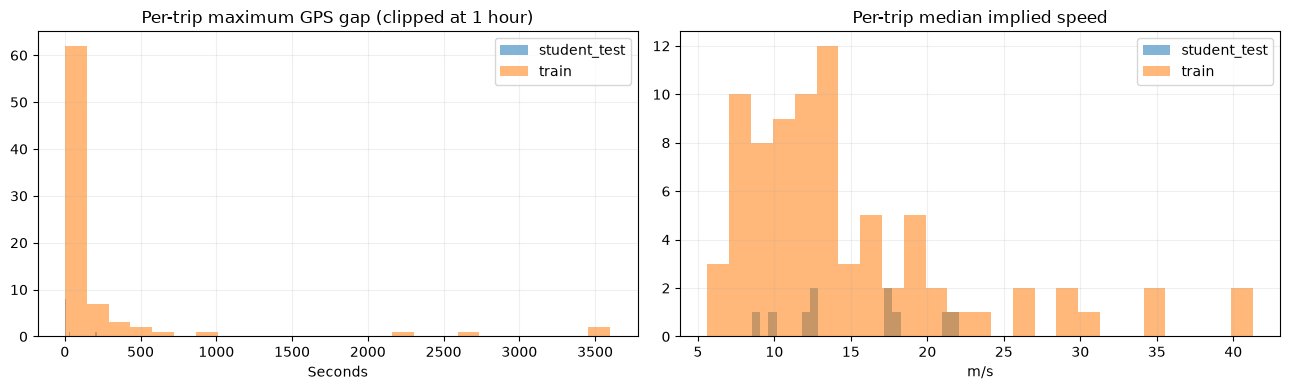

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for partition, group in gps_quality.groupby("partition"):
    axes[0].hist(group["max_gap_s"].clip(upper=3600), bins=25, alpha=.55, label=partition)
    axes[1].hist(group["median_implied_speed_mps"], bins=25, alpha=.55, label=partition)
axes[0].set_title("Per-trip maximum GPS gap (clipped at 1 hour)")
axes[0].set_xlabel("Seconds")
axes[1].set_title("Per-trip median implied speed")
axes[1].set_xlabel("m/s")
for ax in axes: ax.legend(); ax.grid(alpha=.2)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "gps_quality_distributions.png", dpi=160)
plt.show()


In [11]:

# Identify trips with the largest GPS gaps
display(
    gps_quality[
        [
            "partition",
            "trip_id",
            "max_gap_s",
            "median_gap_s",
            "median_step_m",
            "median_implied_speed_mps"
        ]
    ]
    .sort_values("max_gap_s", ascending=False)
    .head(10)
)


,partition,trip_id,max_gap_s,median_gap_s,median_step_m,median_implied_speed_mps
72,train,00000090,153064.0,1.0,16.015116,11.244972
61,train,00000078,52810.0,1.0,19.931373,17.743660
55,train,00000069,2658.0,1.0,11.899891,11.857214
16,train,00000021,2161.0,1.0,7.569082,7.568099
8,train,00000011,909.0,1.0,18.982524,18.982524
34,train,00000042,670.0,1.0,12.271354,12.237883
64,train,00000081,536.0,1.0,10.258124,8.450178
18,train,00000024,458.0,1.0,34.388408,34.388408
36,train,00000044,341.0,1.0,14.075505,13.580837
67,train,00000084,312.0,1.0,7.946195,7.932779


In [12]:

# Identify trips with the highest median implied speeds
display(
    gps_quality[
        [
            "partition",
            "trip_id",
            "max_gap_s",
            "median_implied_speed_mps"
        ]
    ]
    .sort_values("median_implied_speed_mps", ascending=False)
    .head(10)
)


,partition,trip_id,max_gap_s,median_implied_speed_mps
0,train,00000001,16.0,41.272214
25,train,00000032,41.0,40.970212
45,train,00000055,184.0,34.462856
18,train,00000024,458.0,34.388408
4,train,00000005,1.0,30.892552
35,train,00000043,230.0,29.010189
10,train,00000013,8.0,28.459028
9,train,00000012,2.0,26.258775
22,train,00000028,196.0,25.707094
76,train,00000096,1.0,24.112234


In [13]:

def diagnose_trip(partition, trip_id):
    folder = DATA_ROOT / partition / trip_id
    t = read_trip(folder, trip_id)["track"].copy()

    dt = t["timestamp"].diff()

    dist = haversine_m(
        t["longitude"].shift(),
        t["latitude"].shift(),
        t["longitude"],
        t["latitude"]
    )

    speed = dist / dt.where(dt > 0)

    segments = pd.DataFrame({
        "timestamp": t["timestamp"],
        "time_gap_s": dt,
        "distance_m": dist,
        "speed_mps": speed,
        "speed_kmh": speed * 3.6
    })

    print(f"\n{'='*65}")
    print(f"TRIP: {trip_id} | PARTITION: {partition}")
    print(f"{'='*65}")

    print("\nLargest time gaps:")
    display(
        segments.nlargest(5, "time_gap_s")
    )

    print("\nHighest implied speeds:")
    display(
        segments.nlargest(5, "speed_mps")
    )

    print("\nSpeed distribution (km/h):")
    print(
        (speed * 3.6).describe(
            percentiles=[0.50, 0.90, 0.95, 0.99]
        ).round(2)
    )


# Investigate trips with extreme temporal gaps
for trip_id in ["00000090", "00000078"] :
    diagnose_trip("train", trip_id)

# Investigate trips with unusually high median speeds
for trip_id in ["00000001", "00000032", "00000024"]:
    diagnose_trip("train", trip_id)



TRIP: 00000090 | PARTITION: train

Largest time gaps:


,timestamp,time_gap_s,distance_m,speed_mps,speed_kmh
535,154034.0,153064.0,3.299719,0.000022,0.000078
384,538.0,18.0,8.215808,0.456434,1.643162
435,678.0,13.0,12.848777,0.988367,3.558123
201,258.0,12.0,20.243574,1.686965,6.073072
483,854.0,12.0,10.778158,0.898180,3.233447



Highest implied speeds:


,timestamp,time_gap_s,distance_m,speed_mps,speed_kmh
99,138.0,1.0,33.773084,33.773084,121.583104
124,163.0,1.0,33.339274,33.339274,120.021388
150,189.0,1.0,32.651666,32.651666,117.545999
95,134.0,1.0,31.975156,31.975156,115.110560
102,141.0,1.0,31.478741,31.478741,113.323468



Speed distribution (km/h):
count    535.00
mean      44.87
std       27.59
min        0.00
50%       40.48
90%       83.71
95%       92.87
99%      112.95
max      121.58
dtype: float64

TRIP: 00000078 | PARTITION: train

Largest time gaps:


,timestamp,time_gap_s,distance_m,speed_mps,speed_kmh
2,52814.0,52810.0,2.523423,0.000048,0.000172
1320,55176.0,33.0,4.818232,0.146007,0.525625
28,53106.0,26.0,3.256524,0.125251,0.450903
1326,55222.0,25.0,9.576470,0.383059,1.379012
23,53027.0,23.0,8.543655,0.371463,1.337268


... (11 outputs left out)

,timestamp,time_gap_s,distance_m,speed_mps,speed_kmh
155,893.0,458.0,6.255051,0.013657,0.049166
142,407.0,249.0,7.016667,0.028179,0.101446
139,152.0,9.0,14.420700,1.602300,5.768280
143,413.0,6.0,18.636500,3.106083,11.181900
138,143.0,3.0,15.422528,5.140843,18.507034



Highest implied speeds:


,timestamp,time_gap_s,distance_m,speed_mps,speed_kmh
763,1505.0,1.0,65.739037,65.739037,236.660532
765,1507.0,1.0,62.230128,62.230128,224.028460
760,1502.0,1.0,62.128348,62.128348,223.662053
754,1496.0,1.0,60.334059,60.334059,217.202613
53,54.0,1.0,60.154478,60.154478,216.556122



Speed distribution (km/h):
count    800.00
mean     119.10
std       40.68
min        0.05
50%      123.80
90%      166.33
95%      181.37
99%      204.14
max      236.66
dtype: float64


In [14]:

def inspect_speed_events(trip_id, start_idx, end_idx):

    t = read_trip(
        DATA_ROOT / "train" / trip_id,
        trip_id
    )["track"].copy()

    dt = t["timestamp"].diff()

    dist = haversine_m(
        t["longitude"].shift(),
        t["latitude"].shift(),
        t["longitude"],
        t["latitude"]
    )

    speed = dist / dt.where(dt > 0)

    result = t.copy()

    result["time_gap_s"] = dt
    result["distance_m"] = dist
    result["speed_kmh"] = speed * 3.6

    columns = [
        "longitude",
        "latitude",
        "timestamp",
        "time_gap_s",
        "distance_m",
        "speed_kmh"
    ]

    display(
        result.loc[
            start_idx:end_idx,
            columns
        ].round(6)
    )


# Inspect high-speed region in Trip 1
inspect_speed_events("00000001", 90, 105)

# Inspect high-speed region in Trip 32
inspect_speed_events("00000032", 1405, 1420)

# Inspect high-speed region in Trip 24
inspect_speed_events("00000024", 745, 770)


,longitude,latitude,timestamp,time_gap_s,distance_m,speed_kmh
90,8.603363,49.884526,91.0,1.0,47.613725,171.409411
91,8.603469,49.884983,92.0,1.0,51.380515,184.969855
92,8.603564,49.885525,93.0,1.0,60.650849,218.343055
93,8.603691,49.885967,94.0,1.0,49.983370,179.940131
94,8.603719,49.886412,95.0,1.0,49.522457,178.280845
95,8.603711,49.886857,96.0,1.0,49.485130,178.146468
96,8.603900,49.887314,97.0,1.0,52.589208,189.321150
97,8.603858,49.887713,98.0,1.0,44.468754,160.087514
98,8.604056,49.888071,99.0,1.0,42.259649,152.134735
99,8.604069,49.888561,100.0,1.0,54.493548,196.176774


,longitude,latitude,timestamp,time_gap_s,distance_m,speed_kmh
1405,12.836215,52.177059,1732.0,1.0,48.679853,175.247470
1406,12.837515,52.177838,1734.0,2.0,123.938497,223.089295
1407,12.837842,52.178153,1735.0,1.0,41.521083,149.475898
1408,12.838524,52.178654,1736.0,1.0,72.566783,261.240417
1409,12.839046,52.178920,1737.0,1.0,46.278227,166.601617
1410,12.839489,52.179422,1738.0,1.0,63.468437,228.486374
1411,12.840005,52.179702,1739.0,1.0,46.980732,169.130637
1412,12.840816,52.180262,1740.0,1.0,83.277530,299.799107
1413,12.841042,52.180491,1741.0,1.0,29.763104,107.147174
1414,12.841630,52.180936,1742.0,1.0,63.684619,229.264628


,longitude,latitude,timestamp,time_gap_s,distance_m,speed_kmh
745,8.573089,49.169623,1487.0,1.0,49.709392,178.953813
746,8.572886,49.169178,1488.0,1.0,51.635876,185.889154
747,8.572535,49.168764,1489.0,1.0,52.634602,189.484568
748,8.572348,49.168414,1490.0,1.0,41.224634,148.408681
749,8.572172,49.167962,1491.0,1.0,51.863474,186.708507
750,8.571950,49.167535,1492.0,1.0,50.148694,180.535298
751,8.571723,49.167109,1493.0,1.0,50.161901,180.582845
752,8.571457,49.166674,1494.0,1.0,52.092887,187.534392
753,8.571314,49.166283,1495.0,1.0,44.703148,160.931334
754,8.570945,49.165797,1496.0,1.0,60.334059,217.202613


In [15]:

import folium

def visualize_trip(trip_id):

    trip = read_trip(
        DATA_ROOT / "train" / trip_id,
        trip_id
    )["track"].copy()

    center = [
        trip["latitude"].mean(),
        trip["longitude"].mean()
    ]

    m = folium.Map(
        location=center,
        zoom_start=13,
        tiles="OpenStreetMap"
    )

    coordinates = list(zip(
        trip["latitude"],
        trip["longitude"]
    ))

    # Draw complete GPS trajectory
    folium.PolyLine(
        coordinates,
        color="blue",
        weight=3,
        opacity=0.8,
        tooltip=f"Trip {trip_id}"
    ).add_to(m)

    # Starting point
    folium.Marker(
        coordinates[0],
        tooltip="Start",
        icon=folium.Icon(color="green")
    ).add_to(m)

    # Ending point
    folium.Marker(
        coordinates[-1],
        tooltip="End",
        icon=folium.Icon(color="red")
    ).add_to(m)

    return m


visualize_trip("00000001")


In [16]:
visualize_trip("00000032")

In [17]:
visualize_trip("00000024")

In [ ]:
visualize_trip("00000024")

## 6. Road-network integrity and topology

We validate arc endpoint indices and calculate directed/undirected connectivity diagnostics. Weakly connected components ignore edge direction; they are not equivalent to directed reachability.


In [18]:
def network_diagnostics(nodes, arcs):
    n = len(nodes)
    src = arcs["from_node_id"].to_numpy(dtype=np.int64)
    dst = arcs["to_node_id"].to_numpy(dtype=np.int64)
    valid = (src >= 0) & (src < n) & (dst >= 0) & (dst < n)
    valid_src, valid_dst = src[valid], dst[valid]

    indeg = np.bincount(valid_dst, minlength=n)
    outdeg = np.bincount(valid_src, minlength=n)
    totaldeg = indeg + outdeg

    # Weakly connected components using scipy sparse graph routines.
    try:
        from scipy.sparse import coo_matrix
        from scipy.sparse.csgraph import connected_components
        graph = coo_matrix(
            (np.ones(2*len(valid_src), dtype=np.uint8),
             (np.r_[valid_src, valid_dst], np.r_[valid_dst, valid_src])),
            shape=(n,n)
        ).tocsr()
        n_components, labels = connected_components(graph, directed=False, return_labels=True)
        component_sizes = np.bincount(labels, minlength=n_components)
        largest_share = component_sizes.max() / n if n else np.nan
    except Exception as e:
        n_components, largest_share = np.nan, np.nan
        warnings.warn(f"Component analysis unavailable: {e}")

    duplicate_count = int(arcs.duplicated(["from_node_id","to_node_id"]).sum())
    self_loops = int((src == dst).sum())
    return {
        "node_count": n, "arc_count": len(arcs),
        "invalid_arc_endpoint_rows": int((~valid).sum()),
        "isolated_nodes": int((totaldeg == 0).sum()),
        "self_loop_arcs": self_loops,
        "duplicate_directed_arcs": duplicate_count,
        "weak_components": n_components,
        "largest_weak_component_share": largest_share,
        "median_total_degree": float(np.median(totaldeg)) if n else np.nan,
        "p95_total_degree": float(np.quantile(totaldeg,.95)) if n else np.nan,
        "max_total_degree": int(totaldeg.max()) if n else 0,
    }

network_rows = []
for row in inventory.itertuples(index=False):
    trip = read_trip(Path(row.folder), row.trip_id)
    d = network_diagnostics(trip["nodes"], trip["arcs"])
    d.update({"partition": row.partition, "trip_id": row.trip_id})
    network_rows.append(d)

network_summary = pd.DataFrame(network_rows)
display(network_summary.groupby("partition").agg({
    "node_count":["sum","median"], "arc_count":["sum","median"],
    "invalid_arc_endpoint_rows":"sum", "isolated_nodes":"sum",
    "self_loop_arcs":"sum", "duplicate_directed_arcs":"sum",
    "weak_components":["sum","median"],
    "largest_weak_component_share":"median"
}).round(4))
network_summary.to_csv(TABLE_DIR / "network_topology_by_trip.csv", index=False)


node_count         arc_count          invalid_arc_endpoint_rows  \
                    sum  median       sum   median                       sum   
partition                                                                      
student_test      90689  6596.5    185041  13145.0                         0   
train           1933485  9608.0   3876904  19526.5                         0   

             isolated_nodes self_loop_arcs duplicate_directed_arcs  \
                        sum            sum                     sum   
partition                                                            
student_test              0              2                     128   
train                     0             22                    1775   

             weak_components        largest_weak_component_share  
                         sum median                       median  
partition                                                         
student_test             227   11.0                       0.9706  
train                   3121   20.0                       0.9811

## 7. Reference-route validation and directed continuity

A route entry is an arc ID. Consecutive route arcs are directly connected in directed order when the first arc's destination node equals the next arc's source node.


In [19]:
route_rows = []
for row in inventory.itertuples(index=False):
    trip = read_trip(Path(row.folder), row.trip_id)
    arcs, route = trip["arcs"], trip["route"]["arc_id"].to_numpy(dtype=np.int64)
    valid_ids = (route >= 0) & (route < len(arcs))
    valid_route = route[valid_ids]
    connected = np.nan
    if len(valid_route) >= 2:
        src = arcs.iloc[valid_route]["from_node_id"].to_numpy()
        dst = arcs.iloc[valid_route]["to_node_id"].to_numpy()
        connected = float(np.mean(dst[:-1] == src[1:]))
    route_rows.append({
        "partition": row.partition, "trip_id": row.trip_id,
        "route_entries": len(route),
        "invalid_route_arc_ids": int((~valid_ids).sum()),
        "directed_connected_transitions": (
            int(np.sum(dst[:-1] == src[1:])) if len(valid_route) >= 2 else 0
        ),
        "transitions_checked": max(len(valid_route)-1, 0),
        "directed_connectivity_rate": connected,
    })

route_quality = pd.DataFrame(route_rows)
display(route_quality.groupby("partition").agg({
    "route_entries":"sum",
    "invalid_route_arc_ids":"sum",
    "directed_connected_transitions":"sum",
    "transitions_checked":"sum",
    "directed_connectivity_rate":["median","min"]
}).round(5))
route_quality.to_csv(TABLE_DIR / "route_quality_by_trip.csv", index=False)


route_entries invalid_route_arc_ids  \
                       sum                   sum   
partition                                          
student_test          3477                     0   
train                31336                     0   

             directed_connected_transitions transitions_checked  \
                                        sum                 sum   
partition                                                         
student_test                           3466                3467   
train                                 31243               31256   

             directed_connectivity_rate           
                                 median      min  
partition                                         
student_test                        1.0  0.99732  
train                               1.0  0.98131

## 8. GPS path length versus reference-route length

This is a diagnostic comparison, not a direct accuracy metric. GPS path length can be inflated by noise and gaps; reference-route length is the sum of arc geometry lengths.


In [20]:
length_rows = []
for row in inventory.itertuples(index=False):
    trip = read_trip(Path(row.folder), row.trip_id)
    t, nodes, arcs = trip["track"], trip["nodes"], trip["arcs"]
    gps_step = haversine_m(t["longitude"].shift(), t["latitude"].shift(),
                           t["longitude"], t["latitude"])
    gps_length = float(gps_step.sum(skipna=True))

    route_ids = trip["route"]["arc_id"].to_numpy(dtype=np.int64)
    valid = (route_ids >= 0) & (route_ids < len(arcs))
    selected = arcs.iloc[route_ids[valid]]
    if len(selected):
        coords_from = nodes.iloc[selected["from_node_id"].to_numpy()]
        coords_to = nodes.iloc[selected["to_node_id"].to_numpy()]
        route_lengths = haversine_m(
            coords_from["longitude"].to_numpy(), coords_from["latitude"].to_numpy(),
            coords_to["longitude"].to_numpy(), coords_to["latitude"].to_numpy()
        )
        route_length = float(np.sum(route_lengths))
    else:
        route_length = 0.0

    length_rows.append({
        "partition": row.partition, "trip_id": row.trip_id,
        "gps_path_length_m": gps_length,
        "reference_route_length_m": route_length,
        "reference_to_gps_length_ratio": route_length/gps_length if gps_length > 0 else np.nan
    })

length_comparison = pd.DataFrame(length_rows)
display(length_comparison.groupby("partition").agg({
    "gps_path_length_m":"median",
    "reference_route_length_m":"median",
    "reference_to_gps_length_ratio":["median","min","max"]
}).round(3))
length_comparison.to_csv(TABLE_DIR / "gps_vs_reference_route_length.csv", index=False)


gps_path_length_m reference_route_length_m  \
                        median                   median   
partition                                                 
student_test         20935.617                14733.036   
train                24065.719                14295.853   

             reference_to_gps_length_ratio                
                                    median    min    max  
partition                                                 
student_test                         0.866  0.440  0.952  
train                                0.844  0.133  0.993

## 9. Visualize one representative trip

This creates a static GPS trajectory plot. Folium map generation is provided as an optional next cell.


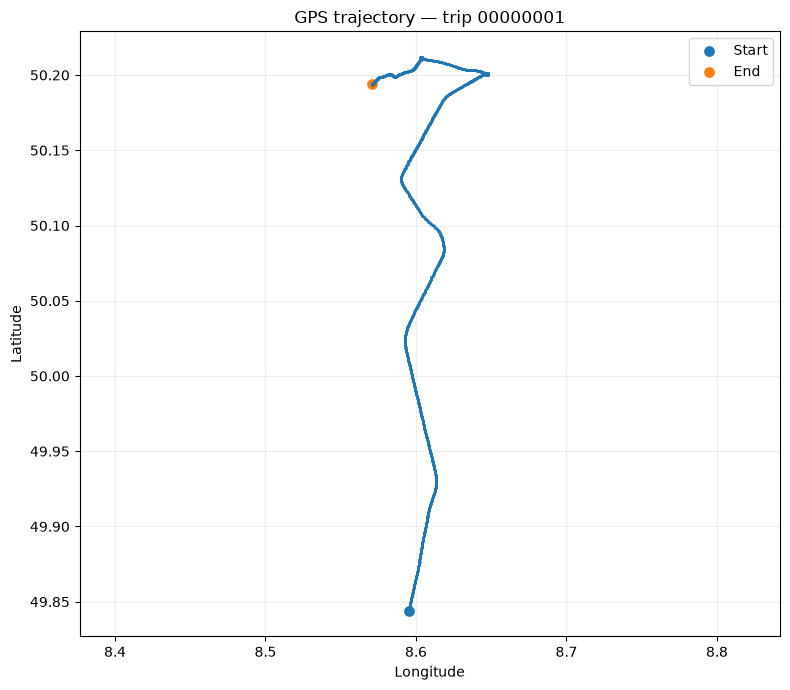

In [22]:
# Select one training trip for a first visual inspection.
example_row = inventory[inventory["partition"] == "train"].iloc[0]
example_id = example_row["trip_id"]
example = read_trip(Path(example_row["folder"]), example_id)
track = example["track"]

plt.figure(figsize=(8, 7))
plt.plot(track["longitude"], track["latitude"], linewidth=.8, marker=".", markersize=2)
plt.scatter(track["longitude"].iloc[0], track["latitude"].iloc[0], label="Start", s=45)
plt.scatter(track["longitude"].iloc[-1], track["latitude"].iloc[-1], label="End", s=45)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title(f"GPS trajectory — trip {example_id}")
plt.legend()
plt.axis("equal")
plt.grid(alpha=.2)
plt.tight_layout()
plt.savefig(FIGURE_DIR / f"gps_trajectory_{example_id}.png", dpi=160)
plt.show()


## 10. Optional Folium map

Folium is optional for this first setup. This cell maps the GPS observations and reference-route arc geometry. For very large trips, sample GPS points for display to keep the HTML manageable.


In [24]:

try:
    import folium
    from folium import plugins

    # Sample GPS points only for rendering; analysis above uses the full data.
    map_track = track.iloc[::max(1, len(track)//3000)].copy()
    center = [
        float(track["latitude"].median()),
        float(track["longitude"].median())
    ]

    fmap = folium.Map(
        location=center,
        zoom_start=13,
        control_scale=True
    )

    # GPS trajectory
    gps_coords = map_track[["latitude", "longitude"]].to_numpy().tolist()

    folium.PolyLine(
        gps_coords,
        color="blue",
        weight=3,
        opacity=.8,
        name="GPS trajectory"
    ).add_to(fmap)

    # GPS marker clustering (corrected)
    marker_cluster = plugins.MarkerCluster().add_to(fmap)

    for r in map_track.itertuples(index=False):
        folium.Marker(
            location=[r.latitude, r.longitude]
        ).add_to(marker_cluster)

    # Reference route geometry, if all referenced arcs are valid.
    route_ids = example["route"]["arc_id"].to_numpy(dtype=np.int64)

    if len(route_ids) and np.all(
        (route_ids >= 0) & (route_ids < len(example["arcs"]))
    ):
        route_arcs = example["arcs"].iloc[route_ids]
        route_nodes = example["nodes"]
        route_coords = []

        for arc in route_arcs.itertuples(index=False):
            a = route_nodes.iloc[int(arc.from_node_id)]
            b = route_nodes.iloc[int(arc.to_node_id)]

            route_coords.extend([
                [float(a.latitude), float(a.longitude)],
                [float(b.latitude), float(b.longitude)]
            ])

        folium.PolyLine(
            route_coords,
            color="green",
            weight=4,
            opacity=.8,
            name="Reference route"
        ).add_to(fmap)

    # Map controls
    folium.LayerControl().add_to(fmap)

    # Save interactive map
    map_path = MAP_DIR / f"trip_{example_id}_eda.html"
    fmap.save(str(map_path))

    print("Saved map:", map_path.resolve())

except ImportError:
    print("Folium not installed. Install it with: pip install folium")


Saved map: /Users/kcnandan/Desktop/PathSnap_EDA_Project/outputs/maps/trip_00000001_eda.html


In [ ]:
visualize_trip("00000024")

## 11. Export a concise EDA findings summary

The CSV outputs are the detailed evidence. This cell writes a small JSON summary for later reporting.


In [26]:

import json

# Helper: convert DataFrames into JSON-safe records
def safe_records(df):
    cleaned = df.astype(object).where(pd.notna(df), None)
    return cleaned.to_dict(orient="records")


# 1. GPS quality by partition
gps_partition_summary = (
    gps_quality.groupby("partition")
    .agg(
        trip_count=("trip_id", "nunique"),
        median_max_gap_s=("max_gap_s", "median"),
        worst_gap_s=("max_gap_s", "max"),
        median_gap_s=("median_gap_s", "median"),
        median_step_m=("median_step_m", "median"),
        median_implied_speed_mps=("median_implied_speed_mps", "median")
    )
    .reset_index()
)


# 2. Network topology by partition
network_partition_summary = (
    network_summary.groupby("partition")
    .agg(
        total_nodes=("node_count", "sum"),
        median_nodes=("node_count", "median"),
        total_arcs=("arc_count", "sum"),
        median_arcs=("arc_count", "median"),
        invalid_arc_endpoint_rows=("invalid_arc_endpoint_rows", "sum"),
        isolated_nodes=("isolated_nodes", "sum"),
        self_loop_arcs=("self_loop_arcs", "sum"),
        duplicate_directed_arcs=("duplicate_directed_arcs", "sum"),
        weak_components=("weak_components", "sum"),
        median_weak_component_share=("largest_weak_component_share", "median")
    )
    .reset_index()
)


# 3. Route validation by partition
route_partition_summary = (
    route_quality.groupby("partition")
    .agg(
        route_entries=("route_entries", "sum"),
        invalid_route_arc_ids=("invalid_route_arc_ids", "sum"),
        connected_transitions=("directed_connected_transitions", "sum"),
        transitions_checked=("transitions_checked", "sum"),
        median_connectivity=("directed_connectivity_rate", "median"),
        minimum_connectivity=("directed_connectivity_rate", "min")
    )
    .reset_index()
)


# 4. GPS versus reference route length
length_partition_summary = (
    length_comparison.groupby("partition")
    .agg(
        median_gps_length_m=("gps_path_length_m", "median"),
        median_reference_length_m=("reference_route_length_m", "median"),
        median_length_ratio=("reference_to_gps_length_ratio", "median"),
        minimum_length_ratio=("reference_to_gps_length_ratio", "min"),
        maximum_length_ratio=("reference_to_gps_length_ratio", "max")
    )
    .reset_index()
)


# 5. Identify major GPS gap anomalies
largest_gap_trips = (
    gps_quality.sort_values("max_gap_s", ascending=False)
    [["partition", "trip_id", "max_gap_s",
      "median_gap_s", "median_implied_speed_mps"]]
    .head(5)
)


# 6. Identify unusually high implied-speed trips
highest_speed_trips = (
    gps_quality.sort_values(
        "median_implied_speed_mps", ascending=False
    )
    [["partition", "trip_id", "max_gap_s",
      "median_implied_speed_mps"]]
    .head(5)
)


# 7. Build comprehensive EDA summary
eda_summary = {
    "trip_counts": (
        inventory.groupby("partition")["trip_id"]
        .nunique().to_dict()
    ),

    "gps_observations": (
        trip_summary.groupby("partition")["gps_observations"]
        .sum().to_dict()
    ),

    "road_nodes": (
        trip_summary.groupby("partition")["road_nodes"]
        .sum().to_dict()
    ),

    "road_arcs": (
        trip_summary.groupby("partition")["road_arcs"]
        .sum().to_dict()
    ),

    "reference_route_entries": (
        trip_summary.groupby("partition")["reference_route_entries"]
        .sum().to_dict()
    ),

    "gps_quality": safe_records(gps_partition_summary),

    "largest_gps_gap_trips": safe_records(largest_gap_trips),

    "highest_median_speed_trips": safe_records(highest_speed_trips),

    "network_topology": safe_records(network_partition_summary),

    "route_validation": safe_records(route_partition_summary),

    "gps_vs_reference_route_length": safe_records(
        length_partition_summary
    )
}


# 8. Export JSON
summary_path = TABLE_DIR / "eda_summary.json"

summary_path.write_text(
    json.dumps(
        eda_summary,
        indent=2,
        default=lambda x: x.item() if hasattr(x, "item") else str(x)
    )
)

print("EDA summary successfully exported:")
print(summary_path.resolve())

print("\nEDA outputs saved under:")
print(OUTPUT_ROOT.resolve())


EDA summary successfully exported:
/Users/kcnandan/Desktop/PathSnap_EDA_Project/outputs/tables/eda_summary.json

EDA outputs saved under:
/Users/kcnandan/Desktop/PathSnap_EDA_Project/outputs


## 12. Interpretation checklist

Complete this after running the notebook and reviewing the generated outputs.

- [ ] Confirm partition and trip counts.
- [ ] Review missing/invalid GPS observations.
- [ ] Inspect extreme GPS gaps and implied speeds by trip.
- [ ] Inspect coordinate extents and representative trajectories.
- [ ] Review road-network component sizes and directed connectivity.
- [ ] Investigate duplicate arcs while preserving original arc IDs.
- [ ] Validate reference route arc IDs and directed transitions.
- [ ] Investigate trips with large GPS/reference distance discrepancies.
- [ ] Save representative Folium maps.
- [ ] Record decisions and assumptions before preprocessing or model training.

**Do not treat preliminary findings from earlier discussions as ground truth. Use the outputs generated by this notebook as the reproducible record.**
